[← PT-09 RLOO (REINFORCE Leave-One-Out)](PT_09_rloo_from_scratch_toy_env-CSharp.ipynb) | [↑ PostTraining](README.md) | [PT-11a GRPO + RLVR sur Qwen3.5-0.8B →](PT_11a_grpo_qwen35_rlvr.ipynb)

**Jumeau** · [Python](PT_10_gae_from_scratch_toy_env.ipynb)
***

# PT-10 C# — GAE from scratch : pourquoi un mini-critic ? (et quand n'en faut-il pas)

**Pourquoi ce notebook ?** PT-08 (GRPO) et PT-09 (RLOO) ont montré qu'on peut **remplacer un critic** par une **statistique du groupe** (group-mean ou leave-one-out) sur un env à reward **1-step sparse**. GAE (Generalized Advantage Estimation, Schulman 2015) est le **3ᵉ pilier** du post-training moderne : il **utilise un mini-critic** (1 value head) pour réduire la **variance de l'avantage** par bootstrapping, et un paramètre λ pour interpoler entre **TD(0)** (bootstrap : **biais plus élevé** — la cible dépend du V appris — mais **variance plus basse**) et **Monte-Carlo** (return échantillonné : **non biaisé on-policy**, **variance plus élevée**).

**Ce qu'on va mesurer** : sur le banc à huit actions de PT-09 vérifié par Z3 (équation `s² + a == b`, racine carrée entière dans `{0..7}`, 8 actions, reward binaire 1-step), on compare **3 estimateurs** de l'avantage sur **5 seeds × 100 epochs** (K=4 samples par prompt) :

| Estimateur | Critic | λ | Formule (1-step) | Params supp. |
|---|---|---|---|---|
| REINFORCE + batch baseline | non | — | `A_t = R_t - mean(R_batch)` | 0 |
| GAE(λ=0) TD(0) | oui | 0 | `A_t = r_t - V(s_t)` | 65 |
| GAE(λ=0.95) | oui | 0.95 | (1-step collapse) `A_t = r_t - V(s_t)` | 65 |

**Ce que le banc distingue** : en une étape, le calcul de GAE se réduit à TD(0) et λ disparaît. Les courbes et l’écart apparié mesurent le coût et la performance du critic avec ces graines. DeepSeek-R1 (2025) utilise GRPO, introduit dans DeepSeekMath (2024). PT-12 étudie une expérience multi-étape où toute la séquence compte. [DeepSeek-R1](https://arxiv.org/abs/2501.12948) · [DeepSeekMath](https://arxiv.org/abs/2402.03300).

**Continuité de la série** : PT-04 (GRPO via `trl`) → PT-08 (GRPO from-scratch) → PT-09 (RLOO from-scratch, leave-one-out) → **PT-10 (GAE from-scratch, mini-critic)**. On reste sur CPU, MLP ~8.7k params (actor+critic), toy env vérifiable (RLVR).

**Pré-requis** : PT-08, PT-09 (même toy env).

**Prérequis C#** · .NET Interactive, TorchSharp CPU, Z3 4.12.2. La configuration Linux figure dans le README.
**Durée pédagogique** · 45 min.

In [1]:
#r "nuget: TorchSharp-cpu, 0.107.0"
#r "nuget: Microsoft.Z3, 4.12.2"
using System;
using System.Collections.Generic;
using System.Globalization;
using System.IO;
using System.Linq;
using System.Runtime.InteropServices;
using System.Text;
using TorchSharp;
using static TorchSharp.torch;
using Microsoft.DotNet.Interactive.Formatting;
using Z3 = Microsoft.Z3;

// Le moteur managé et la bibliothèque Z3 native doivent correspondre sur Linux.
if (RuntimeInformation.IsOSPlatform(OSPlatform.Linux))
{
    string cheminZ3 = Environment.GetEnvironmentVariable("Z3_NATIVE_LIBRARY");
    if (string.IsNullOrWhiteSpace(cheminZ3) || !File.Exists(cheminZ3))
        throw new InvalidOperationException("Configurer Z3_NATIVE_LIBRARY avant de lancer le noyau (voir README).");
    NativeLibrary.SetDllImportResolver(typeof(Z3.Context).Assembly,
        (nom, assembly, recherche) => nom == "libz3" ? NativeLibrary.Load(cheminZ3) : IntPtr.Zero);
}
torch.set_num_threads(1);
torch.manual_seed(42);
Console.WriteLine($".NET {Environment.Version}, TorchSharp CPU 0.107.0, threads={torch.get_num_threads()}, Z3 {Z3.Version.FullVersion}, graine 42.");

Installed Packages Microsoft.Z3, 4.12.2 TorchSharp-cpu, 0.107.0

Loading extensions from `/workspace/coursia-toolchains/nuget/skiasharp/2.88.6/interactive-extensions/dotnet/SkiaSharp.DotNet.Interactive.dll`

.NET 10.0.14, TorchSharp CPU 0.107.0, threads=1, Z3 Z3 4.12.2.0, graine 42.


## 1. L’environnement vérifié par Z3

Le banc de PT-09 vérifie $s^2+a=b$ avec $a\in\{0,\ldots,5\}$ et $s\in\{0,\ldots,7\}$. Les réponses justes reçoivent 1 et les autres 0. Les premiers appels à Z3 vérifient l’équivalence des prédicats et montrent quatre exemples de racines. Le prédicat vectorisé sert aux mises à jour en une étape.

L’encodage concatène 6 coordonnées one-hot pour $a$ et 55 pour $b$. Le diagnostic multi-étape appelle Z3 pour chaque réponse terminale.

In [2]:
const int MaxA = 5, Actions = 8, MaxB = (Actions - 1) * (Actions - 1) + MaxA;
const int Invites = 32, Semence = 42;
const double Taux = 5e-3;
var contexte = new Z3.Context();
var solutionZ3 = contexte.MkIntConst("s");
var solveur = contexte.MkSolver();
bool VerifierZ3(int a, int b, int s)
{
    // Push/Pop isolent la contrainte de chaque réponse tout en réutilisant le moteur.
    using var termeA = contexte.MkInt(a);
    using var termeB = contexte.MkInt(b);
    using var termeS = contexte.MkInt(s);
    using var borneInferieure = contexte.MkInt(0);
    using var borneSuperieure = contexte.MkInt(Actions);
    using var carre = contexte.MkMul(solutionZ3, solutionZ3);
    using var somme = contexte.MkAdd(carre, termeA);
    using var egalite = contexte.MkEq(somme, termeB);
    using var min = contexte.MkGe(solutionZ3, borneInferieure);
    using var max = contexte.MkLt(solutionZ3, borneSuperieure);
    using var fixation = contexte.MkEq(solutionZ3, termeS);
    solveur.Push();
    try
    {
        solveur.Add(egalite, min, max, fixation);
        return solveur.Check() == Z3.Status.SATISFIABLE;
    }
    finally
    {
        solveur.Pop();
    }
}
bool Predicat(int a, int b, int s) => s >= 0 && s < Actions && s * s + a == b;
Tensor Recompense(Tensor a, Tensor b, Tensor s) =>
    ((s * s + a).eq(b).logical_and(s.ge(0)).logical_and(s.lt(Actions))).to_type(ScalarType.Float32);

(long[] A, long[] B) Lot(Random alea, int invites, int repetitions = 1)
{
    var a = new long[invites * repetitions];
    var b = new long[invites * repetitions];
    for (int i = 0; i < invites; i++)
    {
        int decalage = alea.Next(MaxA + 1), racine = alea.Next(Actions);
        // La racine est cachée. On duplique la même invite pour ses réponses indépendantes.
        Array.Fill(a, decalage, i * repetitions, repetitions);
        Array.Fill(b, racine * racine + decalage, i * repetitions, repetitions);
    }
    return (a, b);
}
Tensor LogProbasChoisies(Tensor logProbas, Tensor actions) =>
    logProbas.gather(1, actions.unsqueeze(1)).squeeze(1);
Tensor Tirer(Tensor logProbas) => logProbas.exp().multinomial(1).squeeze(1);

var aleaPreuve = new Random(Semence);
var preuves = new List<(int A, int B, int S)>();
// Les 384 triplets valides de ce domaine sont testés exhaustivement.
for (int a = 0; a <= MaxA; a++)
    for (int r = 0; r < Actions; r++)
        for (int s = 0; s < Actions; s++)
            preuves.Add((a, r * r + a, s));
// Les cas frontières comportent aussi des faux candidats, des b inatteignables et des réponses hors domaine.
while (preuves.Count < 2400)
    preuves.Add((aleaPreuve.Next(MaxA + 1), aleaPreuve.Next(-5, MaxB + 6), aleaPreuve.Next(-2, Actions + 3)));
using (var preuve = torch.NewDisposeScope())
{
    var attendu = preuves.Select(p => VerifierZ3(p.A, p.B, p.S) ? 1f : 0f).ToArray();
    var a = torch.tensor(preuves.Select(p => (long)p.A).ToArray());
    var b = torch.tensor(preuves.Select(p => (long)p.B).ToArray());
    var s = torch.tensor(preuves.Select(p => (long)p.S).ToArray());
    var vecteur = Recompense(a, b, s).data<float>().ToArray();
    int ecarts = vecteur.Zip(attendu).Count(p => p.First != p.Second);
    int ecartsScaler = preuves.Select((p, i) => Predicat(p.A, p.B, p.S) == (attendu[i] == 1)).Count(ok => !ok);
    if (ecarts != 0 || ecartsScaler != 0)
        throw new InvalidOperationException("Divergence entre la récompense de l'entraînement et le SMT.");
    Console.WriteLine($"Z3 et récompense tensorielle : {preuves.Count} vérifications, {ecarts} divergence côté tenseurs, {ecartsScaler} côté scalaire.");
}
var exemples = Lot(new Random(100), 4);
foreach (var (a, b) in exemples.A.Zip(exemples.B))
{
    var racines = Enumerable.Range(0, Actions).Where(s => VerifierZ3((int)a, (int)b, s));
    Console.WriteLine($"(a={a}, b={b}) → solutions Z3 [{string.Join(", ", racines)}].");
}
var aleaActions = new Random(2);
var aleaInvites = Lot(new Random(0), 4000);
int succesHasard = aleaInvites.A.Zip(aleaInvites.B)
    .Count(p => Predicat((int)p.First, (int)p.Second, aleaActions.Next(Actions)));
Console.WriteLine($"Hasard : {succesHasard}/4000 = {succesHasard / 4000.0:F3}, référence 1/{Actions} = {1.0 / Actions:F3}.");

Z3 et récompense tensorielle : 2400 vérifications, 0 divergence côté tenseurs, 0 côté scalaire.


(a=5, b=6) → solutions Z3 [1].


(a=4, b=53) → solutions Z3 [7].


(a=2, b=51) → solutions Z3 [7].


(a=4, b=20) → solutions Z3 [4].


Hasard : 518/4000 = 0.130, référence 1/8 = 0.125.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply r

## 2. La policy : MLP acteur + value head (1 mini-critic)

On définit un **MLP partagé** (backbone) avec deux têtes :
- **Actor** : sort une distribution sur les 8 actions (racine carrée prédite).
- **Critic (value head)** : sort une estimation scalaire `V(s) ≈ E[Σ rewards]`. C'est le **mini-critic** — 1 seule tête linéaire (65 params sur ce toy).

PPO peut utiliser la même tête de valeur. Dans PT-08, les quatre époques réutilisent ses trajectoires. Ici la perte d’acteur utilise directement les log-probabilités échantillonnées et la perte de valeur entraîne une tête.

**Coût paramétrique du critic** : hidden=64 → couche `Linear(64, 1)` = 65 params (64 weights + 1 bias). C'est ~0.7% des params totaux (mesuré empiriquement à la cellule suivante). Ce coût est-il justifié ? C'est la question que PT-10 va trancher empiriquement.

In [3]:
const int DimA = MaxA + 1, DimB = MaxB + 1, Cache = 64;
const int Epoques = 100, Echantillons = 4;
record Agent(torch.nn.Module<Tensor, Tensor> Tronc, torch.nn.Module<Tensor, Tensor> Acteur,
    torch.nn.Module<Tensor, Tensor> Valeur) : IDisposable
{
    public (Tensor Logits, Tensor V) Predire(Tensor entree)
    {
        var h = Tronc.forward(entree);
        return (Acteur.forward(h), Valeur.forward(h).squeeze(1));
    }
    public IEnumerable<TorchSharp.Modules.Parameter> Parametres() =>
        Tronc.parameters().Concat(Acteur.parameters()).Concat(Valeur.parameters());
    public void Dispose()
    {
        Tronc.Dispose();
        Acteur.Dispose();
        Valeur.Dispose();
    }
}
Agent CreerAgent(int entree, int actions) => new(
    nn.Sequential(nn.Linear(entree, Cache), nn.ReLU(), nn.Linear(Cache, Cache), nn.ReLU()),
    nn.Linear(Cache, actions), nn.Linear(Cache, 1));
long nombreActeur, nombreCritic;
using (var exemple = CreerAgent(DimA + DimB, Actions))
{
    // Le tronc et la tête de logits constituent ensemble l'acteur.
    nombreActeur = exemple.Tronc.parameters().Concat(exemple.Acteur.parameters()).Sum(p => p.numel());
    nombreCritic = exemple.Valeur.parameters().Sum(p => p.numel());
}
if ((nombreActeur, nombreCritic) != (8648, 65))
    throw new InvalidOperationException("Le budget des deux têtes a changé.");
Console.WriteLine($"Acteur {nombreActeur} paramètres ; critic {nombreCritic} ; total {nombreActeur + nombreCritic}.");
Console.WriteLine($"Surcoût critic/acteur {100.0 * nombreCritic / nombreActeur:F1} %, critic/total {100.0 * nombreCritic / (nombreActeur + nombreCritic):F1} %.");

Acteur 8648 paramètres ; critic 65 ; total 8713.


Surcoût critic/acteur 0.8 %, critic/total 0.7 %.


## 3. REINFORCE : la baseline batch (rappel PT-08)

L'algorithme historique (Williams, 1992) du policy gradient avec **baseline constant** :

$$\nabla_\theta J(\theta) = \mathbb{E}_\tau\left[\nabla_\theta \log \pi_\theta(a_t|s_t) \cdot (R_t - b)\right]$$

où $b$ est une baseline (souvent la moyenne du batch). Une baseline **indépendante de l'action** réduit la variance **sans introduire de biais** (Williams 1992) ; la moyenne du batch contient le reward du sample lui-même et n'en est donc pas exactement une — relation exacte au facteur $1-1/N$ en section 7. PT-08 présente aussi cette baseline de lot, avec son propre domaine d’actions.

Ici on l'utilise comme **référence** : tout gain de GAE sur ce baseline est ce qu'on cherche à mesurer.

In [4]:
Tensor Encoder(Tensor a, Tensor b)
{
    var onehotA = nn.functional.one_hot(a, DimA).to_type(ScalarType.Float32);
    var onehotB = nn.functional.one_hot(b, DimB).to_type(ScalarType.Float32);
    return torch.cat(new[] {onehotA, onehotB}, dim: 1);
}
(Tensor R, Tensor LogP, Tensor Valeurs) Collecter(Agent agent, int prompts, int k, int graine)
{
    // K actions conditionnelles indépendantes pour chaque prompt du lot avant la mise à jour.
    var (a, b) = Lot(new Random(graine), prompts, k);
    var at = torch.tensor(a);
    var bt = torch.tensor(b);
    var (logits, valeurs) = agent.Predire(Encoder(at, bt));
    var logp = logits.log_softmax(1);
    var actions = Tirer(logp);
    return (Recompense(at, bt, actions), LogProbasChoisies(logp, actions), valeurs);
}
Tensor AvantageLot(Tensor r) => r - r.mean();
double[] EntrainerReinforce(int epoques = Epoques, int prompts = Invites,
    int k = Echantillons, int graine = Semence)
{
    torch.manual_seed(graine);
    using var modele = CreerAgent(DimA + DimB, Actions);
    using var adam = torch.optim.Adam(modele.Parametres(), lr: Taux);
    var history = new double[epoques];
    for (int ep = 0; ep < epoques; ep++)
    {
        using var lot = torch.NewDisposeScope();
        var (r, logp, _) = Collecter(modele, prompts, k, graine + ep);
        var perte = -(logp * AvantageLot(r)).mean();
        adam.zero_grad();
        perte.backward();
        adam.step();
        history[ep] = r.mean().item<float>();
    }
    return history;
}
void ImprimerEpoques(string nom, double[] history)
{
    for (int ep = 0; ep < history.Length; ep++)
        if (ep % 20 == 0 || ep == history.Length - 1)
            Console.WriteLine($"{nom,-14} époque {ep,3} : récompense moyenne {history[ep]:F3}.");
}
var reinforce42 = EntrainerReinforce();
ImprimerEpoques("REINFORCE", reinforce42);

REINFORCE      époque   0 : récompense moyenne 0.141.


REINFORCE      époque  20 : récompense moyenne 0.133.


REINFORCE      époque  40 : récompense moyenne 0.367.


REINFORCE      époque  60 : récompense moyenne 0.422.


REINFORCE      époque  80 : récompense moyenne 0.594.


REINFORCE      époque  99 : récompense moyenne 0.875.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy



## 4. GAE : l'avantage bootstrappé via value head

GAE (Schulman et al., 2015) définit l'avantage comme une **moyenne géométrique** pondérée par λ des n-step advantages :

$$A_t^{GAE(\lambda)} = \sum_{l=0}^{T-1-t} (\gamma\lambda)^l \delta_{t+l}$$

où $\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$ est le **TD-error**. Le paramètre λ ∈ [0, 1] contrôle le compromis biais-variance :

- **λ=0** : pure TD(0), 1-step bootstrap — **biais plus élevé** (la cible dépend du $V$ appris), **variance plus basse**.
- **λ=1** : Monte-Carlo, rollout complet — **biais plus faible** (return échantillonné, non biaisé on-policy), **variance plus élevée**.
- **λ=0.95** (OpenAI canonical, Schulman 2015) : compromis pratique entre les deux.

Le **value head** $V(s_\phi)$ est entraîné conjointement avec l'actor via MSE sur les **returns** (avantage + valeur courante). C'est le **mini-critic** : 1 seule tête linéaire.

**Piège d'implémentation (corrigé dans ce notebook)** : pour que cette MSE entraîne réellement le critic, les valeurs $V(s)$ collectées au rollout doivent **rester dans le graphe de calcul** (pas de `.item()`), et la cible (le return) doit au contraire être **détachée** — sinon le gradient traverse les deux opérandes de la MSE et s'annule. Une version antérieure détachait les valeurs des deux côtés : la `v_loss` était une constante, le critic restait gelé à son initialisation (poids inchangés, vérifié : delta exactement 0), et aucune comparaison d'estimateurs n'était alors possible.

In [5]:
Tensor AvantageUnPas(Tensor r, Tensor prediction) => r - prediction.detach();
(double[] Trajectoire, double VariationCritic) EntrainerGae(double lambda = 0.95,
    int epoques = Epoques, int prompts = Invites, int k = Echantillons, int graine = Semence)
{
    torch.manual_seed(graine);
    using var modele = CreerAgent(DimA + DimB, Actions);
    using var adam = torch.optim.Adam(modele.Parametres(), lr: Taux);
    using var preuve = torch.NewDisposeScope();
    var poidsCritic = modele.Valeur.parameters().First();
    var poidsAvant = poidsCritic.detach().clone();
    var historique = new double[epoques];
    for (int ep = 0; ep < epoques; ep++)
    {
        using var lot = torch.NewDisposeScope();
        var (r, logp, valeurs) = Collecter(modele, prompts, k, graine + ep);
        // La terminalité immédiate élimine la dépendance à lambda et tout bootstrap.
        var adv = AvantageUnPas(r, valeurs);
        var retour = adv + valeurs.detach();
        var perteActeur = -(logp * adv).mean();
        // Seule cette branche garde V(s) dans le graphe et entraîne le critic.
        var perteCritic = nn.functional.mse_loss(valeurs, retour);
        var perte = perteActeur + 0.5 * perteCritic;
        adam.zero_grad();
        perte.backward();
        adam.step();
        historique[ep] = r.mean().item<float>();
    }
    return (historique, (poidsCritic - poidsAvant).abs().sum().item<float>());
}
var td42 = EntrainerGae(0);
var gae42 = EntrainerGae(0.95);
ImprimerEpoques("GAE (λ=0)", td42.Trajectoire);
bool identique = td42.Trajectoire.SequenceEqual(gae42.Trajectoire);
if (!identique || !double.IsFinite(td42.VariationCritic) || td42.VariationCritic <= 0)
    throw new InvalidOperationException("Le contrôle de l'indépendance de λ ou de l'apprentissage du critic a échoué.");
Console.WriteLine($"GAE λ=0 / λ=0.95, trajectoires identiques : {identique}.");
Console.WriteLine($"Variation L1 des poids du critic sur la graine 42 : {td42.VariationCritic:F4}.");

GAE (λ=0)      époque   0 : récompense moyenne 0.141.


GAE (λ=0)      époque  20 : récompense moyenne 0.102.


GAE (λ=0)      époque  40 : récompense moyenne 0.258.


GAE (λ=0)      époque  60 : récompense moyenne 0.320.


GAE (λ=0)      époque  80 : récompense moyenne 0.594.


GAE (λ=0)      époque  99 : récompense moyenne 0.812.


GAE λ=0 / λ=0.95, trajectoires identiques : True.


Variation L1 des poids du critic sur la graine 42 : 2.2635.


## 5. Comparaison multi-seed : REINFORCE vs GAE-TD0 vs GAE-0.95

Un seul seed n'est pas statistiquement significatif. On entraîne les 3 méthodes sur **5 seeds** (0, 7, 42, 99, 123) et on compare la distribution du **reward final** (epoch 99) et de la **trajectoire** (epochs 0-99).

In [6]:
var graines = new[] {0, 7, 42, 99, 123};
var methodes = new[] {"REINFORCE", "GAE-TD0", "GAE-0.95"};
var trajectoires = methodes.ToDictionary(nom => nom, _ => new List<double[]>());
foreach (int graine in graines)
{
    var r = EntrainerReinforce(graine: graine);
    var td = EntrainerGae(0, graine: graine);
    var gae = EntrainerGae(0.95, graine: graine);
    if (!td.Trajectoire.SequenceEqual(gae.Trajectoire) || td.VariationCritic <= 0 || gae.VariationCritic <= 0)
        throw new InvalidOperationException($"Contrôle de graine invalide : {graine}.");
    trajectoires["REINFORCE"].Add(r);
    trajectoires["GAE-TD0"].Add(td.Trajectoire);
    trajectoires["GAE-0.95"].Add(gae.Trajectoire);
    Console.WriteLine($"Graine {graine,3} | REINFORCE {r[^1]:F3} | GAE-TD0 {td.Trajectoire[^1]:F3} | GAE-0.95 {gae.Trajectoire[^1]:F3}.");
}
double[] Fin(string nom) => trajectoires[nom].Select(h => h[^1]).ToArray();
double Dispersion(double[] v)
{
    double moyenne = v.Average();
    return Math.Sqrt(v.Average(x => (x - moyenne) * (x - moyenne)));
}
Console.WriteLine($"{"Méthode",-12} {"Moyenne",8} {"Écart type",11} {"Min",6} {"Max",6}");
foreach (string nom in methodes)
{
    var valeurs = Fin(nom);
    Console.WriteLine($"{nom,-12} {valeurs.Average(),8:F3} {Dispersion(valeurs),11:F3} {valeurs.Min(),6:F3} {valeurs.Max(),6:F3}");
}
// Comparer le delta pour la même graine, plutôt que deux dispersions marginales.
var deltas = Fin("GAE-TD0").Zip(Fin("REINFORCE")).Select(p => p.First - p.Second).ToArray();
double erreurStandard = Dispersion(deltas) / Math.Sqrt(graines.Length - 1);
string statistique = erreurStandard > 0 ? $"{deltas.Average() / erreurStandard:F3}" : "écarts constants";
Console.WriteLine($"Δ apparié GAE − REINFORCE : {deltas.Average():F3}, t = {statistique}, deltas positifs {deltas.Count(x => x > 0)}/{graines.Length}.");
Console.WriteLine($"Trajectoires GAE identiques aux deux λ, pour {graines.Length}/{graines.Length} graines.");

Graine   0 | REINFORCE 0.719 | GAE-TD0 0.836 | GAE-0.95 0.836.


Graine   7 | REINFORCE 0.742 | GAE-TD0 0.703 | GAE-0.95 0.703.


Graine  42 | REINFORCE 0.875 | GAE-TD0 0.812 | GAE-0.95 0.812.


Graine  99 | REINFORCE 0.961 | GAE-TD0 0.859 | GAE-0.95 0.859.


Graine 123 | REINFORCE 0.758 | GAE-TD0 0.820 | GAE-0.95 0.820.


Méthode       Moyenne  Écart type    Min    Max


REINFORCE       0.811       0.092  0.719  0.961


GAE-TD0         0.806       0.054  0.703  0.859


GAE-0.95        0.806       0.054  0.703  0.859


Δ apparié GAE − REINFORCE : -0.005, t = -0.115, deltas positifs 2/5.


Trajectoires GAE identiques aux deux λ, pour 5/5 graines.


## 6. Visualisation : trajectoires superposées

Chaque courbe donne la moyenne de cinq trajectoires. La bande est la moyenne plus ou moins un écart-type inter-graines. La superposition des deux courbes GAE est contrôlée à chaque étape, pour toutes les graines.

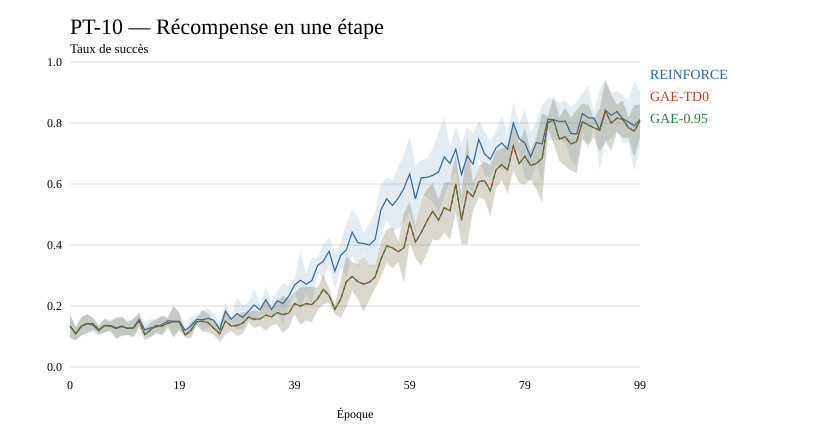

In [7]:
record CourbesSvg(string Contenu);
Formatter.Register<CourbesSvg>((courbes, writer) => writer.Write(courbes.Contenu), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(CourbesSvg), "image/svg+xml");
string Dessin(FormattableString texte) => texte.ToString(CultureInfo.InvariantCulture);
string Echapper(string texte) => System.Net.WebUtility.HtmlEncode(texte);
double EcartType(IReadOnlyCollection<double> valeurs)
{
    double m = valeurs.Average();
    return Math.Sqrt(valeurs.Average(x => (x - m) * (x - m)));
}
void Tracer(
    string titre, string abscisse, (string Nom, string Couleur, double[] Moyenne, double[] Dispersion)[] series,
    double? hasard = null)
{
    const int largeur = 820, hauteur = 440;
    int n = series[0].Moyenne.Length;
    double X(int t) => 70 + 570.0 * t / (n - 1);
    double Y(double r) => 367 - 305 * Math.Clamp(r, 0, 1);
    string Points(IReadOnlyList<double> serie) =>
        string.Join(" ", serie.Select((valeur, t) => Dessin($"{X(t):F2},{Y(valeur):F2}")));
    var svg = new StringBuilder(Dessin($"<svg xmlns='http://www.w3.org/2000/svg' width='{largeur}' height='{hauteur}' viewBox='0 0 {largeur} {hauteur}' role='img'><title>{Echapper(titre)}</title><rect width='100%' height='100%' fill='white'/>"));
    svg.Append(Dessin($"<text x='70' y='34' font-size='22'>{Echapper(titre)}</text><text x='70' y='53' font-size='13'>Taux de succès</text>"));
    for (int i = 0; i <= 5; i++)
    {
        double r = i / 5.0;
        svg.Append(Dessin($"<path d='M70 {Y(r):F2} H640' stroke='#DDD'/><text x='62' y='{Y(r)+4:F2}' text-anchor='end'>{r:F1}</text>"));
        int t = i * (n - 1) / 5;
        svg.Append(Dessin($"<text x='{X(t):F2}' y='389' text-anchor='middle'>{t}</text>"));
    }
    svg.Append(Dessin($"<text x='355' y='418' text-anchor='middle'>{Echapper(abscisse)}</text>"));
    if (hasard.HasValue)
        svg.Append(Dessin($"<path d='M70 {Y(hasard.Value):F2} H640' stroke='#555' stroke-dasharray='5 4'/><text x='650' y='{Y(hasard.Value)+4:F2}'>Hasard</text>"));
    for (int j = 0; j < series.Length; j++)
    {
        var s = series[j];
        // Bande ± écart type autour de la trajectoire multi-graines, quand une dispersion est mesurée.
        if (s.Dispersion.Length != 0)
        {
            var haut = s.Moyenne.Zip(s.Dispersion).Select(p => p.First + p.Second).ToArray();
            var bas = s.Moyenne.Zip(s.Dispersion).Select(p => p.First - p.Second).ToArray();
            string retour = string.Join(" ", bas.Select((v, i) => Dessin($"{X(i):F2},{Y(v):F2}")).Reverse());
            svg.Append(Dessin($"<polygon points='{Points(haut)} {retour}' fill='{s.Couleur}' fill-opacity='0.13'/>"));
        }
        string tirets = j == 2 ? " stroke-dasharray='4 3'" : "";
        svg.Append(Dessin($"<polyline points='{Points(s.Moyenne)}' fill='none' stroke='{s.Couleur}' stroke-width='1.2'{tirets}/>"));
        svg.Append(Dessin($"<text x='650' y='{79 + 22*j}' fill='{s.Couleur}' font-size='14'>{Echapper(s.Nom)}</text>"));
    }
    display(new CourbesSvg(svg.Append("</svg>").ToString()));
}

// La bande se calcule indépendamment pour chaque époque, à partir des cinq trajectoires.
var couleurs = new[] {"#2d66a1", "#b7442a", "#2d7d40"};
var courbes = methodes.Select((nom, i) =>
{
    var epochs = Enumerable.Range(0, Epoques);
    var moyennes = epochs.Select(ep => trajectoires[nom].Average(h => h[ep])).ToArray();
    var ecarts = epochs.Select(ep => EcartType(trajectoires[nom].Select(h => h[ep]).ToArray())).ToArray();
    return (nom, couleurs[i], moyennes, ecarts);
}).ToArray();
Tracer("PT-10 — Récompense en une étape", "Époque", courbes);

## 7. Interprétation : pourquoi GAE collapse en 1-step

Le tableau compare cinq trajectoires appariées. La dispersion et l’écart apparié se lisent en sortie. Le nombre de graines est faible pour généraliser à d’autres bancs. Voici la raison algébrique de l’égalité entre les deux λ :

**L'env z3 est 1-step** : l'épisode se termine après une seule action. Dans ce cas, la formule générale de GAE se réduit à :

$$A_t^{GAE(\lambda)} = r_t + \gamma V(s_{t+1}) - V(s_t)$$

avec $V(s_{t+1}) = 0$ (état terminal). Donc **$A_t = r_t - V(s_t)$**, indépendamment de λ — la section 4 le démontre par le code : les trajectoires λ=0 et λ=0.95 sont **strictement identiques** (λ n'entre dans aucune formule). Le paramètre λ n'agit qu'en multi-step : pour $\lambda \in (0, 1]$, on somme $(γλ)^l \delta_{t+l}$ sur $l = 0, 1, ..., T-t-1$. En 1-step, cette somme est triviale (un seul terme).

**Conséquence** : sur 1-step, GAE utilise $A_t = r_t - V(s_t)$ et REINFORCE $A_t = r_t - \bar{R}_{batch}$ — deux estimateurs **différents**, sans théorème d'équivalence entre eux. $V(s)$ est une fonction de l'état seulement, **indépendante de l'action** : elle laisse l'espérance du gradient **exactement inchangée** (Williams 1992). La batch-mean de `AvantageLot` (§3) contient le **reward du sample lui-même** : elle n'est pas indépendante de l'action pour ce sample — sous indépendance conditionnelle des samples du batch, l'espérance de l'estimateur est **mise à l'échelle par $1-1/N$** par rapport à la version sans baseline (même direction, magnitude réduite ; ici $N = 32 \times 4 = 128$, facteur $\approx 0.992$ — négligeable en pratique, mais c'est une différence de nature, pas une équivalence ; c'est précisément ce que le leave-one-out de PT-09 corrige en excluant le sample courant).

Le tableau rapporte la dispersion inter-graines des récompenses finales et le delta apparié sur cinq graines. Cette dispersion ne mesure pas directement la variance du gradient. La tête de valeur ajoute 65 paramètres. L’expérience établit l’égalité des deux λ sur les trajectoires observées et chiffre la comparaison avec la baseline de lot à ce budget.

DeepSeek-R1 (2025) utilise GRPO, introduit par DeepSeekMath (2024). Le coût d’une tête de valeur dans un LLM dépasse le périmètre de ce banc. [DeepSeek-R1](https://arxiv.org/abs/2501.12948) · [DeepSeekMath](https://arxiv.org/abs/2402.03300).

### Exercice 1 — GAE-AVG

Former un quatrième estimateur en moyennant l’avantage sur le lot et celui basé sur la valeur. Garder la perte de valeur différentiable. Comparer la récompense et la variance sur les mêmes cinq graines, époques et tailles de lot que les autres estimateurs.

In [8]:
// TODO : combiner les deux baselines sans détacher la perte de valeur elle-même.
// A_t = 0,5 (R − mean(R)) + 0,5 (r − V(s)), à comparer à budgets et graines identiques.
Func<int, int, int, int, double[]> entrainerGaeAvg = null;
Console.WriteLine("Exercice 1 à compléter : GAE-AVG et comparaison sur cinq graines.");

Exercice 1 à compléter : GAE-AVG et comparaison sur cinq graines.


## 8. Diagnostic multi-step : une première tentative, et pourquoi elle ne prouvait rien

Pour montrer **quand** GAE apporte un bénéfice, cette section entraîne le même mini-critic (désormais **réellement entraîné**, section 4) sur un env **multi-step vérifié par z3** : l'agent émet 3 tokens, les deux premiers sont des **estimations** de la racine (reward shaped sur le résidu), le troisième est la **réponse terminale** vérifiée par z3 (`s^2 + a == b`). La question : λ devient-il discriminant quand l'horizon passe à 3 ?

**Réponse mesurée ci-dessous : non — et le diagnostic est instructif.** Ce banc a **deux défauts structurels** (diagnostiqués a posteriori dans PT-12) :

1. **La cible est inobservable dans l'état** : l'observation ne contient que les tokens déjà émis, jamais `(a, b)`. La policy ne peut pas résoudre le problème — seulement apprendre une distribution stationnaire de tokens, sans crédit différé exploitable.
2. **Le vérificateur terminal ne regarde que le dernier token** : la contribution marginale des tokens 1-2 au reward terminal est nulle — l'horizon de crédit effectif retombe à 1.

On garde ce banc comme **témoin du diagnostic** : on y mesure le reward moyen d'épisode (dominé par le shaping) **et** le **taux de succès terminal** (la métrique honnête). PT-12 construit le banc valide — cible **dans** l'état, terminal dépendant de **toute** la séquence — et y mesure la vraie discrimination de λ (`GAE-λ=0.95` bat `GAE-λ=0` sur 5 seeds sur 5, deltas appariés tous positifs).


In [9]:
const int Vocabulaire = 10, Horizon = 3, EpoquesMulti = 30, EpisodesMulti = 64;
const int ResiduelMax = (Vocabulaire - 1) * (Vocabulaire - 1) + MaxA;
const double W = 0.1, Gamma = 0.99;
(double[] Reward, double[] Terminal) EntrainerMulti(double lambda, int epoques = EpoquesMulti,
    int trajets = EpisodesMulti, int graine = Semence)
{
    torch.manual_seed(graine);
    using var modele = CreerAgent(Horizon, Vocabulaire);
    using var adam = torch.optim.Adam(modele.Parametres(), lr: Taux);
    var reward = new double[epoques];
    var terminal = new double[epoques];
    for (int ep = 0; ep < epoques; ep++)
    {
        using var lot = torch.NewDisposeScope();
        var (a, b) = Lot(new Random(graine + ep), trajets);
        var prefixes = new float[trajets * Horizon];
        var logp = new Tensor[Horizon];
        var valeurs = new Tensor[Horizon];
        var numeriques = new float[Horizon][];
        var r = new float[Horizon * trajets];
        for (int t = 0; t < Horizon; t++)
        {
            // Chaque entrée ne reçoit que les tokens déjà émis. La cible reste volontairement cachée.
            var entrees = torch.tensor(prefixes).reshape(trajets, Horizon);
            var (logits, v) = modele.Predire(entrees);
            var l = logits.log_softmax(1);
            var action = Tirer(l);
            logp[t] = LogProbasChoisies(l, action);
            valeurs[t] = v;
            numeriques[t] = v.detach().data<float>().ToArray();
            var tokens = action.data<long>().ToArray();
            for (int i = 0; i < trajets; i++)
            {
                int s = (int)tokens[i];
                prefixes[i * Horizon + t] = (float)s / Vocabulaire;
                // Chaque réponse terminale appelle Z3. Les tokens précédents prennent le shaping du résidu.
                r[t * trajets + i] = t == Horizon - 1
                    ? (VerifierZ3((int)a[i], (int)b[i], s) ? 1f : 0f)
                    : (float)(W * Math.Max(0, 1 - Math.Abs(s * s + a[i] - b[i]) / (double)ResiduelMax));
            }
        }
        var avantages = new float[r.Length];
        for (int t = Horizon - 1; t >= 0; t--)
            for (int i = 0; i < trajets; i++)
            {
                int ix = t * trajets + i;
                // La récurrence remonte à l'intérieur de chaque trajectoire, jamais vers l'épisode suivant.
                double dernier = t == Horizon - 1 ? 0 : Gamma * (numeriques[t + 1][i] + lambda * avantages[ix + trajets]);
                avantages[ix] = (float)(r[ix] - numeriques[t][i] + dernier);
            }
        var adv = torch.tensor(avantages);
        var vDiff = torch.cat(valeurs);
        var pertePolitique = -(torch.cat(logp) * adv).mean();
        var perteValeur = nn.functional.mse_loss(vDiff, adv + vDiff.detach());
        var perte = pertePolitique + 0.5 * perteValeur;
        adam.zero_grad();
        perte.backward();
        adam.step();
        reward[ep] = r.Sum() / trajets;
        terminal[ep] = r.Skip((Horizon - 1) * trajets).Average();
    }
    return (reward, terminal);
}
var hasardMulti = new Random(2);
var invitesMulti = Lot(new Random(0), 4000);
int reussitesMulti = invitesMulti.A.Zip(invitesMulti.B)
    .Count(p => VerifierZ3((int)p.First, (int)p.Second, hasardMulti.Next(Vocabulaire)));
Console.WriteLine($"Multi-étape : horizon {Horizon}, témoin uniforme Z3 {reussitesMulti}/4000 = {reussitesMulti / 4000.0:F3}.");
var multi0 = EntrainerMulti(0);
var multi95 = EntrainerMulti(0.95);
foreach (var (nom, resultat) in new[]{("λ=0",multi0),("λ=0.95",multi95)})
    Console.WriteLine($"{nom,-7} : reward {resultat.Reward[0]:F3} → {resultat.Reward[^1]:F3}, succès terminal {resultat.Terminal[0]:F3} → {resultat.Terminal[^1]:F3}.");
Console.WriteLine($"Appels directs Z3 dans ce diagnostic : 4000 + 2 × {EpoquesMulti} × {EpisodesMulti} = {4000 + 2 * EpoquesMulti * EpisodesMulti}.");

Multi-étape : horizon 3, témoin uniforme Z3 378/4000 = 0.095.


λ=0     : reward 0.226 → 0.281, succès terminal 0.094 → 0.125.


λ=0.95  : reward 0.226 → 0.241, succès terminal 0.094 → 0.094.


Appels directs Z3 dans ce diagnostic : 4000 + 2 × 30 × 64 = 7840.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy



## 9. Bilan paramétrique et transfert vers le LLM

En une étape, la perte de politique utilise l’avantage détaché. La perte de valeur garde le gradient jusqu’au critic et utilise la récompense comme cible terminale. La tête de valeur ajoute 65 paramètres à l’acteur. La table et les deltas appariés donnent le résultat sur cinq graines. Une comparaison à cinq graines ne permet pas de démontrer l’équivalence générale.

Le diagnostic séquentiel chiffre séparément le shaping et le succès final. L’état ne contient pas la cible et le dernier token seul détermine la récompense terminale. Ce protocole ne permet donc pas d’attribuer un avantage général à un réglage de λ. Le cas multi-étape de PT-12 rend la cible observable et le succès dépendant de toute la séquence. Le passage aux LLM modifie en plus le coût et l’espace de prédiction de la tête de valeur.

In [10]:
// Comparer le coût du critic et la métrique terminale aux traces d'entraînement, à partir des mesures.
Console.WriteLine($"Une étape : {graines.Length} graines, {Epoques} époques, {Echantillons} réponses par prompt.");
foreach (string nom in methodes)
    Console.WriteLine($"{nom,-13} fin {Fin(nom).Average():F3} ± {Dispersion(Fin(nom)):F3}.");
Console.WriteLine($"Multi-étape naïf : {EpoquesMulti} époques × {EpisodesMulti} épisodes × {Horizon} pas.");
Console.WriteLine($"Succès terminal final : λ=0 {multi0.Terminal[^1]:F3} ; λ=0.95 {multi95.Terminal[^1]:F3}.");
Console.WriteLine("L'état sans cible ne permet pas d'inférer la racine. Comparer la métrique terminale au hasard avant de lire le shaping.");

Une étape : 5 graines, 100 époques, 4 réponses par prompt.


REINFORCE     fin 0.811 ± 0.092.


GAE-TD0       fin 0.806 ± 0.054.


GAE-0.95      fin 0.806 ± 0.054.


Multi-étape naïf : 30 époques × 64 épisodes × 3 pas.


Succès terminal final : λ=0 0.125 ; λ=0.95 0.094.


L'état sans cible ne permet pas d'inférer la racine. Comparer la métrique terminale au hasard avant de lire le shaping.


### Exercice 2 — Diagnostic de λ sur le banc multi-étape

Balayer 0, 0,5 et 0,95 sur les mêmes trois graines. Relever séparément la récompense d’épisode et le taux de succès terminal, puis comparer celui-ci au témoin uniforme. Interpréter le résultat en tenant compte de la cible cachée et du rôle du dernier token. Le banc PT-12 montre l’effet d’une autre représentation d’état.

In [11]:
// TODO : balayer λ pour les mêmes trois graines et relever à la fois le shaping et le succès terminal.
var lambdasExercice = new[] {0.0, 0.5, 0.95};
Dictionary<double, (double Reward, double Terminal)> mesuresExercice = null;
Console.WriteLine("Exercice 2 à compléter : diagnostic multi-étape et comparaison au hasard.");

Exercice 2 à compléter : diagnostic multi-étape et comparaison au hasard.


## 10. Comparer les avantages

Fixer la politique et les tirages permet d’étudier la sensibilité au critic.

### Exercice 3 — Variance des avantages à politique fixée

Pour chacune des dix graines, générer un seul lot de trajectoires et calculer les deux estimateurs sur ce lot. Comparer les variances puis leur dispersion inter-graines. La qualité de la tête de valeur peut faire varier la dispersion dans les deux sens. Cette mesure concerne l’avantage. La variance du gradient dépend aussi des corrélations dans le lot. En variante, ajouter un bruit croissant à la prédiction de valeur et comparer les résultats.

In [12]:
// TODO : fixer une policy. Pour chacune des dix graines réutiliser le même lot pour les deux avantages.
// Faire varier la qualité de V(s) avec un bruit contrôlé et mesurer la variance inter-graines.
Dictionary<int, (double Batch, double Gae)> variancesExercice = null;
Console.WriteLine("Exercice 3 à compléter : variances à politique et trajectoires fixées.");

Exercice 3 à compléter : variances à politique et trajectoires fixées.


## Pour aller plus loin — les étages réels du transfert

Ce banc utilise **8 648 paramètres pour l’acteur et 65 pour la tête de valeur**, soit 8 713 paramètres au total ; les étages réels de la série sont :

- [PT-04 — GRPO avec `trl`, à la main](PT_04_grpo_deepseek_r1.ipynb) : le vrai `GRPOTrainer` (`num_generations: 4`, run de démonstration borné à `max_steps: 3`) — implémentation commentée, l'exécution y est conditionnelle (`LOAD_MODEL_AND_TRAIN`).
- [PT-11a — GRPO réel sur Qwen3.5-0.8B](PT_11a_grpo_qwen35_rlvr.ipynb) : la boucle complète **exécutée** — QLoRA 4-bit (540 672 paramètres entraînables sur 752 933 696), reward Z3, 800 récompenses, moyenne globale 0.1263, max 1.0000.

Précision d'honnêteté sur le bilan du §9 : le « banc valide PT-12 » y est le banc multi-step **toy** de la série (torch + z3, from-scratch) — valide parmi les toys, pas un étage LLM. Aucun notebook de la série n'exécute encore GAE sur un LLM réel : le bilan en une étape décrit ce banc, et le surcoût du critic à l'échelle LLM (ce que DeepSeek R1 a arbitré) n'est pas mesuré ici.